# Experiment 8: Implementing Transformer-Based Models for Text Generation (GPT & BERT)

**Aim:** Implement the two families of Transformer models - a decoder-only **GPT** (causal language model for text
generation) and an encoder-only **BERT** (masked language model) - and train miniature versions on Shakespeare.

*Note:* the execution environment has no access to model hubs, so the models are written with Keras building blocks and
trained from scratch at small scale; the architecture is the same as GPT-2 / BERT, only smaller.

In [1]:
import os, re, time, collections
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(8)
rng = np.random.default_rng(8)
print("TensorFlow", tf.__version__)

I0000 00:00:1792699146.741062   12941 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792699148.251291   12941 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0


## 1. Word-level tokenisation of the corpus

In [2]:
path = keras.utils.get_file("shakespeare.txt", "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
raw = open(path, encoding="utf-8").read().lower()
tokens = re.findall(r"[a-z']+|[.,;:!?\n]", raw)
VOCAB_SIZE = 5000
SPECIAL = ["<pad>", "<unk>", "<mask>"]
common = [w for w, _ in collections.Counter(tokens).most_common(VOCAB_SIZE - len(SPECIAL))]
itos = SPECIAL + common; stoi = {w: i for i, w in enumerate(itos)}
ids = np.array([stoi.get(t, 1) for t in tokens], dtype=np.int32)
PAD, UNK, MASK = 0, 1, 2
print("tokens:", len(ids), "| vocabulary:", len(itos), "| unknown rate: %.2f%%" % (100 * (ids == UNK).mean()))
def decode(seq):
    s = " ".join(itos[i] for i in seq)
    s = re.sub(r" ([.,;:!?])", r"\1", s).replace(" \n ", "\n").replace("\n ", "\n").replace(" \n", "\n")
    return s
print("sample:", repr(decode(ids[:30])))

tokens: 290371 | vocabulary: 5000 | unknown rate: 3.30%
sample: 'first citizen:\nbefore we proceed any further, hear me speak.\n\nall:\nspeak, speak.\n\nfirst citizen:\nyou'


## 2. Transformer building blocks
Multi-head scaled dot-product self-attention: $\mathrm{Attn}(Q,K,V)=\mathrm{softmax}(QK^\top/\sqrt{d_k})V$. GPT uses a
**causal mask** (a token only sees the past); BERT lets every token see the whole sentence.

In [3]:
D, HEADS, FF, LAYERS, DROP = 128, 4, 512, 3, 0.1

class Block(layers.Layer):
    def __init__(self, causal, **kw):
        super().__init__(**kw)
        self.causal = causal
        self.att = layers.MultiHeadAttention(HEADS, D // HEADS)
        self.ln1, self.ln2 = layers.LayerNormalization(epsilon=1e-5), layers.LayerNormalization(epsilon=1e-5)
        self.ff = keras.Sequential([layers.Dense(FF, activation="gelu"), layers.Dense(D)])
        self.drop = layers.Dropout(DROP)
    def call(self, x, training=False, return_scores=False):
        h = self.ln1(x)
        a, s = self.att(h, h, use_causal_mask=self.causal, return_attention_scores=True, training=training)
        x = x + self.drop(a, training=training)
        x = x + self.drop(self.ff(self.ln2(x)), training=training)
        return (x, s) if return_scores else x

class Transformer(keras.Model):
    """causal=True -> GPT (decoder only); causal=False -> BERT (bidirectional encoder)."""
    def __init__(self, causal, ctx, **kw):
        super().__init__(**kw)
        self.tok = layers.Embedding(len(itos), D); self.pos = layers.Embedding(ctx, D)
        self.blocks = [Block(causal) for _ in range(LAYERS)]
        self.ln = layers.LayerNormalization(epsilon=1e-5); self.drop = layers.Dropout(DROP)
        self.head = layers.Dense(len(itos))
    def call(self, x, training=False, return_scores=False):
        T = tf.shape(x)[1]
        h = self.drop(self.tok(x) + self.pos(tf.range(T))[None], training=training)
        scores = []
        for b in self.blocks:
            if return_scores: h, s = b(h, training=training, return_scores=True); scores.append(s)
            else: h = b(h, training=training)
        out = self.head(self.ln(h))
        return (out, scores) if return_scores else out

CTX = 48
gpt = Transformer(True, CTX, name="mini_gpt"); gpt(np.zeros((1, CTX), "int32"))
bert = Transformer(False, 32, name="mini_bert"); bert(np.zeros((1, 32), "int32"))
print(f"mini-GPT : {gpt.count_params():,} parameters ({LAYERS} layers, {HEADS} heads, d_model {D}, context {CTX})")
print(f"mini-BERT: {bert.count_params():,} parameters ({LAYERS} layers, {HEADS} heads, d_model {D}, context 32)")

mini-GPT : 1,886,216 parameters (3 layers, 4 heads, d_model 128, context 48)
mini-BERT: 1,884,168 parameters (3 layers, 4 heads, d_model 128, context 32)


## 3. GPT: causal language modelling and text generation

In [4]:
STRIDE = 12
starts = np.arange(0, len(ids) - CTX - 1, STRIDE)
X = np.stack([ids[s:s + CTX] for s in starts]); Y = np.stack([ids[s + 1:s + CTX + 1] for s in starts])
perm = rng.permutation(len(X)); n_val = len(X) // 20
Xv, Yv, Xt, Yt = X[perm[:n_val]], Y[perm[:n_val]], X[perm[n_val:]], Y[perm[n_val:]]
print("train sequences:", Xt.shape, "| validation sequences:", Xv.shape)
# baseline: bigram model with add-k smoothing
bi = np.ones((len(itos), len(itos))) * 0.05
np.add.at(bi, (ids[:-1], ids[1:]), 1); bi /= bi.sum(1, keepdims=True)
bigram_ppl = float(np.exp(-np.mean(np.log(bi[Xv.ravel(), Yv.ravel()]))))
print("bigram baseline validation perplexity: %.1f  (uniform guessing would give %d)" % (bigram_ppl, len(itos)))

train sequences: (22985, 48) | validation sequences: (1209, 48)


bigram baseline validation perplexity: 85.7  (uniform guessing would give 5000)


In [5]:
sched = keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=(len(Xt) // 64) * 8, alpha=0.05)
gpt.compile(keras.optimizers.Adam(sched, clipnorm=1.0), keras.losses.SparseCategoricalCrossentropy(from_logits=True))
t0 = time.time()
hg = gpt.fit(Xt, Yt, validation_data=(Xv, Yv), batch_size=64, epochs=8, verbose=2).history
print(f"\ntraining time {time.time() - t0:.0f}s | final val loss {hg['val_loss'][-1]:.3f} | "
      f"val perplexity {np.exp(hg['val_loss'][-1]):.1f} (bigram baseline {bigram_ppl:.1f})")

Epoch 1/8


360/360 - 99s - 276ms/step - loss: 4.9991 - val_loss: 4.3624


Epoch 2/8


360/360 - 90s - 251ms/step - loss: 4.2116 - val_loss: 4.0190


Epoch 3/8


360/360 - 90s - 251ms/step - loss: 3.9334 - val_loss: 3.8035


... (7 outputs left out)

360/360 - 92s - 256ms/step - loss: 3.3468 - val_loss: 3.3828


Epoch 8/8


360/360 - 91s - 252ms/step - loss: 3.3038 - val_loss: 3.3626



training time 732s | final val loss 3.363 | val perplexity 28.9 (bigram baseline 85.7)


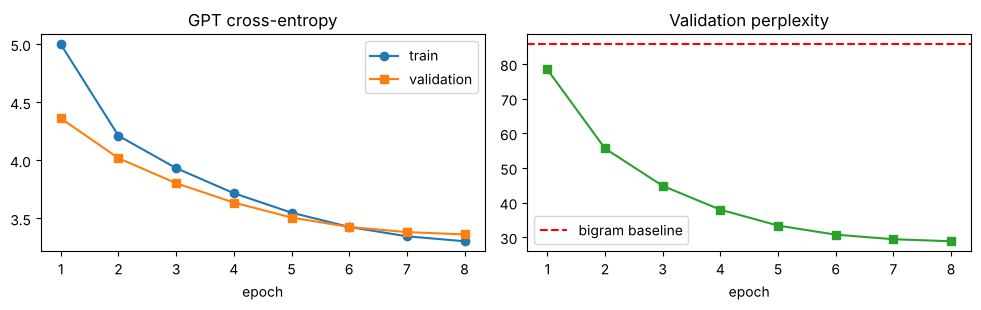

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
e = range(1, 9)
ax[0].plot(e, hg["loss"], "o-", label="train"); ax[0].plot(e, hg["val_loss"], "s-", label="validation"); ax[0].set(title="GPT cross-entropy", xlabel="epoch"); ax[0].legend()
ax[1].plot(e, np.exp(hg["val_loss"]), "s-", c="tab:green"); ax[1].axhline(bigram_ppl, c="r", ls="--", label="bigram baseline")
ax[1].set(title="Validation perplexity", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [7]:
def generate(prompt, n=60, temperature=0.8, top_k=40):
    seq = [stoi.get(t, 1) for t in re.findall(r"[a-z']+|[.,;:!?\n]", prompt.lower())]
    for _ in range(n):
        ctx = np.array([seq[-CTX:]])
        logits = gpt(ctx, training=False)[0, -1].numpy() / temperature
        logits[[PAD, UNK, MASK]] = -1e9
        top = np.argsort(logits)[-top_k:]
        p = np.exp(logits[top] - logits[top].max()); p /= p.sum()
        seq.append(int(rng.choice(top, p=p)))
    return decode(seq)
for prompt, T in (("romeo:\nwhat", 0.7), ("first citizen:\nwe are", 0.8), ("the king", 1.0)):
    print(f"--- prompt {prompt!r}, temperature {T} ---")
    print(generate(prompt, 55, T), "\n")

--- prompt 'romeo:\nwhat', temperature 0.7 ---


romeo:
what, wilt thou not?

nurse:
how fares our princely king?

romeo:
thou art, my lord.

nurse:
the dead!

lady capulet:

nurse:
good morrow, old nurse!

romeo: 

--- prompt 'first citizen:\nwe are', temperature 0.8 ---


first citizen:
we are not quickly the king.

first senator:
and when he stands, he shall
say he is as the city.
this is a traitor to the duke of york,
and his kinsman.

aufidius:
but who was a father?

 

--- prompt 'the king', temperature 1.0 ---


the king!

henry bolingbroke:
that it is so early by marriage,
the royal duke of aumerle was got my lord,
and so i had lost my gracious father and mine
you had been as i; in which that now i shall be
to hear our 



## 4. BERT: masked language modelling
15% of the tokens are selected; of those, 80% are replaced by `<mask>`, 10% by a random word and 10% are kept. The model
must recover the original token using context from **both** sides.

In [8]:
BL = 32
bstarts = np.arange(0, len(ids) - BL, 8)
B = np.stack([ids[s:s + BL] for s in bstarts]); nv = len(B) // 20
Bv, Bt = B[:nv], B[nv:]
def mask_batch(batch, seed):
    r = np.random.default_rng(seed)
    sel = r.random(batch.shape) < 0.15
    inp = batch.copy(); act = r.random(batch.shape)
    inp[sel & (act < 0.8)] = MASK
    rnd = sel & (act >= 0.8) & (act < 0.9); inp[rnd] = r.integers(3, len(itos), rnd.sum())
    return inp, sel.astype("float32")
bert.compile(keras.optimizers.Adam(5e-4, clipnorm=1.0), keras.losses.SparseCategoricalCrossentropy(from_logits=True), weighted_metrics=[])
Xvm, Mv = mask_batch(Bv, 999)
acc_hist, loss_hist = [], []
t0 = time.time()
for ep in range(1, 9):
    Xm, M = mask_batch(Bt, ep)
    h = bert.fit(Xm, Bt, sample_weight=M / M.mean(), batch_size=64, epochs=1, verbose=0).history
    p = bert.predict(Xvm, verbose=0).argmax(-1)
    acc = float(((p == Bv) * Mv).sum() / Mv.sum())
    acc_hist.append(acc); loss_hist.append(h["loss"][0])
    print(f"epoch {ep}/8  masked-LM loss {h['loss'][0]:.3f}  masked-token accuracy on validation {acc:.3f}  ({time.time() - t0:.0f}s)")
top_share = np.bincount(Bv[Mv.astype(bool)]).max() / Mv.sum()
print("Chance level for a 5000-word vocabulary is 0.02 percent; always predicting the most frequent word gives %.1f percent" % (100 * top_share))

epoch 1/8  masked-LM loss 5.475  masked-token accuracy on validation 0.233  (114s)


epoch 2/8  masked-LM loss 4.502  masked-token accuracy on validation 0.279  (216s)


epoch 3/8  masked-LM loss 4.144  masked-token accuracy on validation 0.297  (317s)


epoch 4/8  masked-LM loss 3.961  masked-token accuracy on validation 0.306  (417s)


epoch 5/8  masked-LM loss 3.833  masked-token accuracy on validation 0.315  (518s)


epoch 6/8  masked-LM loss 3.724  masked-token accuracy on validation 0.322  (668s)


epoch 7/8  masked-LM loss 3.652  masked-token accuracy on validation 0.322  (771s)


epoch 8/8  masked-LM loss 3.578  masked-token accuracy on validation 0.334  (871s)
Chance level for a 5000-word vocabulary is 0.02 percent; always predicting the most frequent word gives 14.6 percent


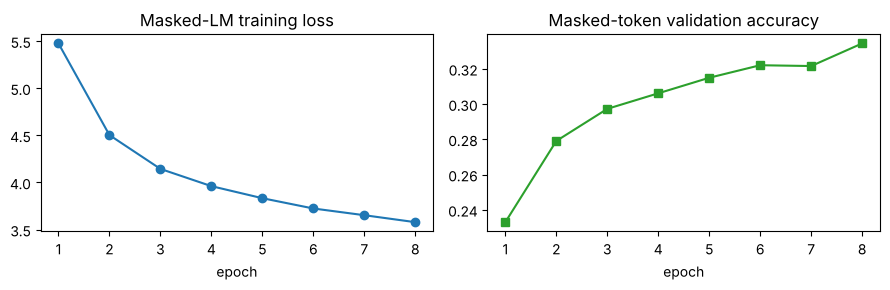

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(range(1, 9), loss_hist, "o-"); ax[0].set(title="Masked-LM training loss", xlabel="epoch")
ax[1].plot(range(1, 9), acc_hist, "s-", c="tab:green"); ax[1].set(title="Masked-token validation accuracy", xlabel="epoch")
plt.tight_layout(); plt.show()

In [10]:
def fill_mask(sentence, k=5):
    toks = re.findall(r"[a-z']+|[.,;:!?\n]|<mask>", sentence.lower())
    seq = [MASK if t == "<mask>" else stoi.get(t, 1) for t in toks]
    seq = (seq + [PAD] * BL)[:BL]
    logits = bert(np.array([seq]), training=False)[0].numpy()
    logits[:, [PAD, UNK, MASK]] = -1e9
    pos = [i for i, t in enumerate(toks) if t == "<mask>"][0]
    p = np.exp(logits[pos] - logits[pos].max()); p /= p.sum()
    top = np.argsort(p)[::-1][:k]
    return [(itos[i], float(p[i])) for i in top]
tests = ["o romeo , romeo ! wherefore art thou <mask> ?", "to be , or not to <mask> , that is the question",
         "i will <mask> you to the king", "good <mask> , my lord ,", "what light through yonder <mask> breaks"]
for s in tests:
    print(s); print("   ->", ", ".join(f"{w!r} ({p:.2f})" for w, p in fill_mask(s)))

o romeo , romeo ! wherefore art thou <mask> ?
   -> 'liest' (0.06), 'art' (0.02), 'not' (0.02), 'hast' (0.02), "know'st" (0.01)
to be , or not to <mask> , that is the question
   -> 'me' (0.07), 'him' (0.04), 'morrow' (0.02), 'know' (0.02), 'love' (0.02)
i will <mask> you to the king
   -> 'make' (0.04), 'take' (0.04), 'bring' (0.03), 'call' (0.02), 'give' (0.02)
good <mask> , my lord ,


   -> 'kate' (0.05), 'lords' (0.04), 'sir' (0.03), 'lord' (0.02), 'night' (0.02)
what light through yonder <mask> breaks
   -> '\n' (0.04), 'eyes' (0.03), 'blood' (0.02), 'death' (0.01), 'strength' (0.01)


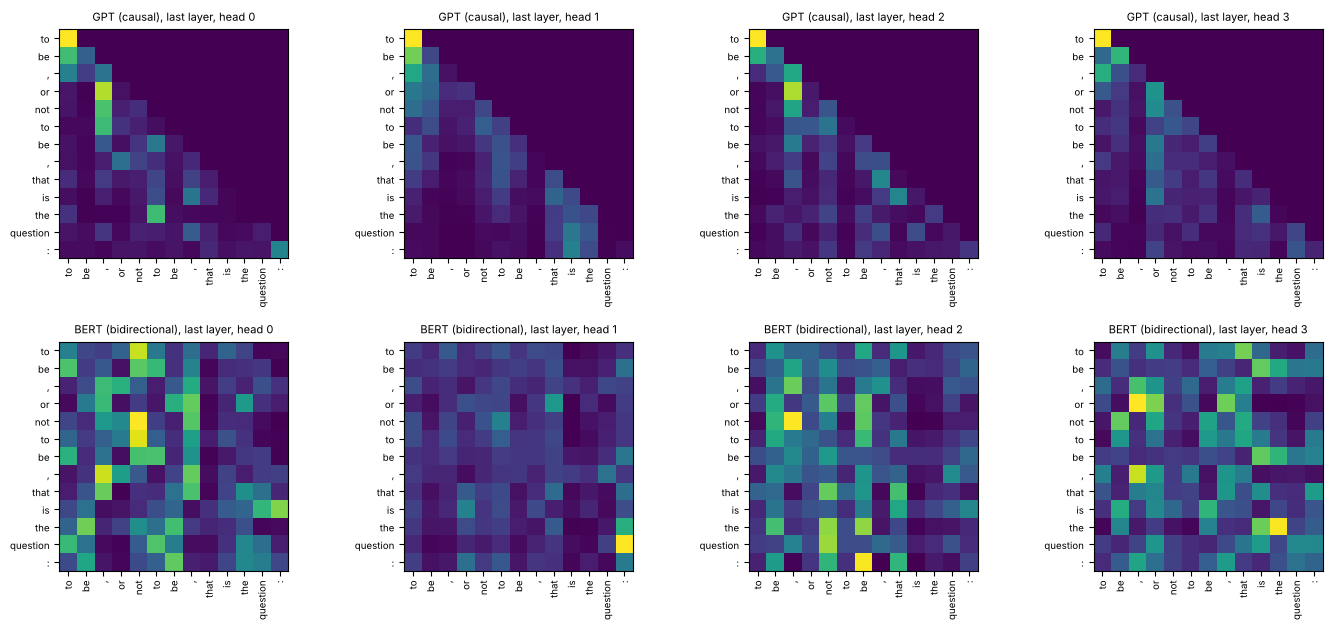

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
sent = "to be , or not to be , that is the question :".split()
ids_s = np.array([[stoi.get(t, 1) for t in sent]])
_, sg = gpt(ids_s, training=False, return_scores=True)
_, sb = bert(ids_s, training=False, return_scores=True)
for r, (name, sc) in enumerate((("GPT (causal)", sg), ("BERT (bidirectional)", sb))):
    for c, head in enumerate(range(4)):
        a = axes[r, c]; a.imshow(sc[-1][0, head].numpy(), cmap="viridis")
        a.set_xticks(range(len(sent))); a.set_xticklabels(sent, rotation=90, fontsize=7)
        a.set_yticks(range(len(sent))); a.set_yticklabels(sent, fontsize=7); a.set_title(f"{name}, last layer, head {head}", fontsize=8)
plt.tight_layout(); plt.show()